### Nugget Regularization Tests

Following the method outlined in Booker 1998, adding a regularization term to the correlation matrix to test effect on stability

In [13]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)
!
print(module_path)


c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels


Optimization terminated successfully.
         Current function value: -119.924453
         Iterations: 21
         Function evaluations: 42
[22.48303223]


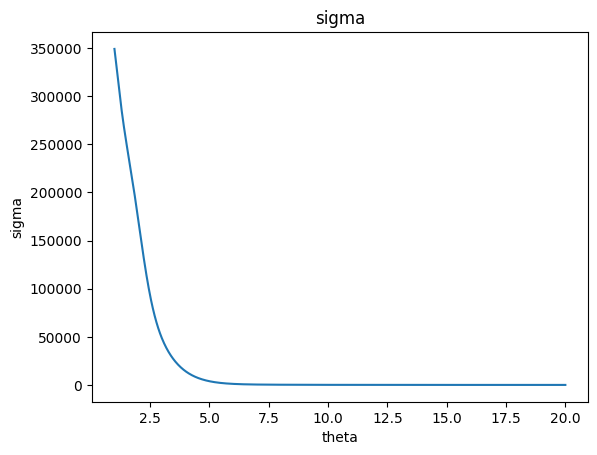

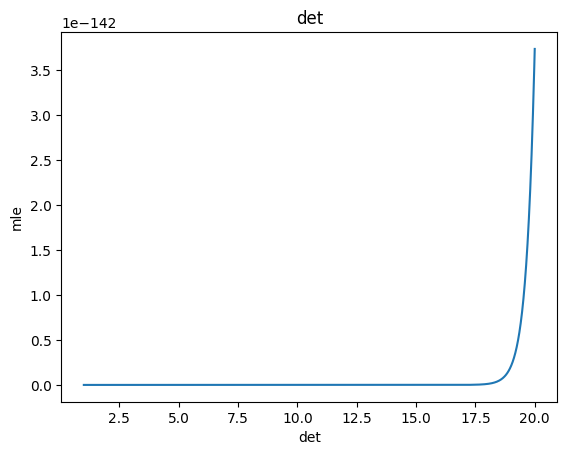

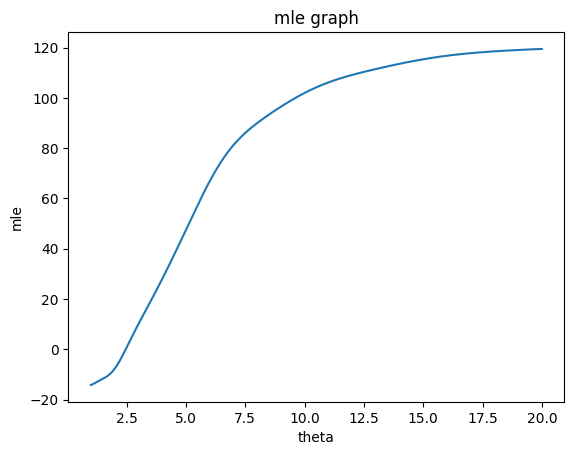

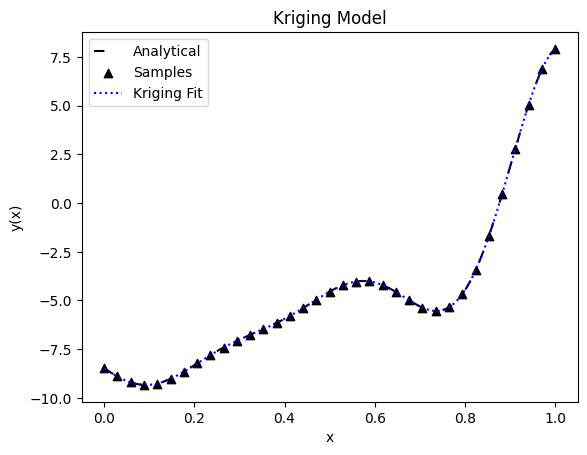

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from SurrogateModels import mfs_functions, kriging

# Start with a synthetic dataset
#rng = np.random.RandomState(0)
fxn_ind = 1
dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

n = 35

x = np.zeros((n,dim), dtype=float)

# Generate the analytical functions
lf_fxn = mfs_functions.cheap_fxn(1)

x[:,0] = np.linspace(xmin,xmax,n)

y = lf_fxn.evaluate(x)
model = kriging.Kriging(x,y,1)

model.plot_MLE()

x_vals = np.ones((300,1))
x_vals[:,0] = np.linspace(0,1,300)

plot_name = "Kriging Model"
lf_fxn.plot_model(x_vals,plot_name, color = "black",
                  linestyle = (0, (5, 10)), label = "Analytical")
model.plot_data(plot_name, color ="black", 
                label = "Samples", marker = '^')
model.plot_model(x_vals, name=plot_name, color="blue",
                    label = "Kriging Fit", linestyle='dotted')
plt.show()

## Kriging Increasing Samples Comparison

C:\Users\troyz\AppData\Local\Temp\ipykernel_3580\1163414751.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('rainbow',8)


Optimization terminated successfully.
         Current function value: 10.924857
         Iterations: 21
         Function evaluations: 42
[22.52557373]
Optimization terminated successfully.
         Current function value: 10.567041
         Iterations: 22
         Function evaluations: 44
[14.09893799]
Optimization terminated successfully.
         Current function value: 7.751125
         Iterations: 21
         Function evaluations: 42
[15.22937012]
Optimization terminated successfully.
         Current function value: -9.759659
         Iterations: 22
         Function evaluations: 44
[15.3470459]
Optimization terminated successfully.
         Current function value: -34.658446
         Iterations: 21
         Function evaluations: 42
[17.42596436]
Optimization terminated successfully.
         Current function value: -61.693817
         Iterations: 21
         Function evaluations: 42
[18.72399902]
Optimization terminated successfully.
         Current function value: -90.242115


c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:104: RuntimeWarning: divide by zero encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\scipy\optimize\_optimize.py:835: RuntimeWarning: invalid value encountered in subtract
  np.max(np.abs(fsim[0] - fsim[1:])) <= fatol):


[40.]


c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:39: RuntimeWarning: Maximum number of function evaluations has been exceeded.
  theta_opt = scipy.optimize.fmin(fun, theta0)


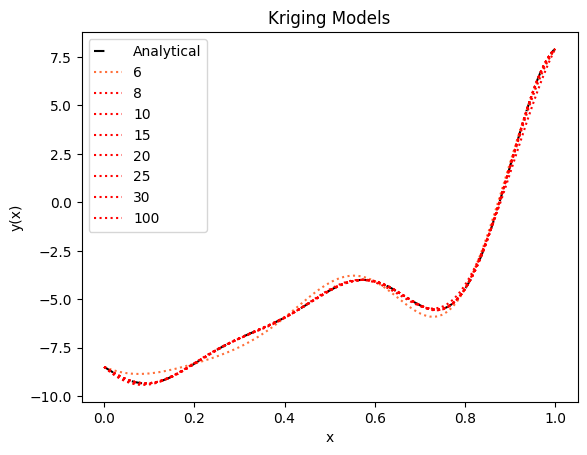

In [19]:
fxn_ind = 1
dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

n_array = [6,8,10,15,20,25,30,100]

x = np.zeros((n,dim), dtype=float)


x_vals = np.ones((300,1))
x_vals[:,0] = np.linspace(0,1,300)

plot_name = "Kriging Models"
lf_fxn.plot_model(x_vals,plot_name, color = "black",
                    linestyle = (0, (5, 10)), label = "Analytical")

cmap = plt.cm.get_cmap('rainbow',8)
# Generate the analytical functions
lf_fxn = mfs_functions.cheap_fxn(1)
for n in n_array:
    
    x = np.zeros((n,dim), dtype=float)
    x[:,0] = np.linspace(xmin,xmax,n)

    y = lf_fxn.evaluate(x)
    model = kriging.Kriging(x,y,1)

    model.plot_model(x_vals, name=plot_name, color=cmap(n),
                        label = str(n), linestyle='dotted')
plt.show()